In [44]:
import os
import matplotlib.pyplot as plt
import torch

"""
P2.01:  Setup: Initial setup and check directory and GPU for problem1
"""
# --- GPU check ---
print('torch:', torch.__version__, '| CUDA:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))

BASE = '/kaggle/working/2026aj05620_DNN_Assignment'
# Ensure the problem2 directory exists and move into it
os.makedirs(f'{BASE}/problem2', exist_ok=True)
os.chdir(f'{BASE}/problem2')

# Set up the figures directory
os.makedirs('figures', exist_ok=True)

# results.csv is at the root of the repo
RESULTS = '../results.csv'

def savefig(name):
    """Save into ./figures/ (created if missing)."""
    os.makedirs('figures', exist_ok=True)
    plt.savefig(os.path.join('figures', name), dpi=150, bbox_inches='tight')

print('cwd:', os.getcwd())
print('RESULTS path:', os.path.abspath(RESULTS))

# Verify the directory is proper
assert os.getcwd() == '/kaggle/working/2026aj05620_DNN_Assignment/problem2'
assert os.path.exists('../results.csv'), "results.csv not found at root! clone the repo!"
print("Setup complete! Inside problem2 directory.")

torch: 2.11.0+cu130 | CUDA: True
GPU: Tesla T4
cwd: /kaggle/working/2026aj05620_DNN_Assignment/problem2
RESULTS path: /kaggle/working/2026aj05620_DNN_Assignment/results.csv
Setup complete! Inside problem2 directory.


In [45]:
import math, time, random
import numpy as np
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import pandas as pd

"""
P2.02:  Imports and Constraints
"""
def set_seed(s):
    random.seed(s); np.random.seed(s)
    torch.manual_seed(s); torch.cuda.manual_seed_all(s)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

#Variant
STUDENT_ID = '2026aj05620'
HIDDEN     = 64          
D_MODEL    = 128         
N_HEADS    = 4           
N_LAYERS   = 2           # For HAR classifier
D_FF       = 512         
SEEDS      = [0, 1, 2]

In [46]:
"""
P2.03:  Task2.1(p2.1):  Attention from scratch.
        Task Desc:      Tests pass; hand example and code agree
        
        Problem 1 starts
        Download and Extract Data
        Define Function sdpa in this cell
            q: (..., Tq, dk)
            k: (..., Tk, dk)
            v: (..., Tk, dv)
            mask: (..., Tq, Tk) bool, True = KEEP, False = -inf
            returns out:(...,Tq,dv), attn:(...,Tq,Tk)
"""
def sdpa(q, k, v, mask=None):
    dk = q.size(-1)
    scores = q @ k.transpose(-2, -1) / math.sqrt(dk)  # (..., Tq, Tk)
    if mask is not None:
        scores = scores.masked_fill(~mask, float('-inf'))
    attn = F.softmax(scores, dim=-1)                  # (..., Tq, Tk)
    return attn @ v, attn

In [47]:
"""
P2.04:  Unit tests
"""
torch.manual_seed(0)
q, k, v = torch.randn(2, 5, 8), torch.randn(2, 5, 8), torch.randn(2, 5, 8)
out, attn = sdpa(q, k, v)

# 1. each row of weights sums to 1
assert torch.allclose(attn.sum(-1), torch.ones(2, 5), atol=1e-6)

# 2. output matches torch library within 1e-5
ref = F.scaled_dot_product_attention(q, k, v)
assert (out - ref).abs().max() < 1e-5

# 3. causal mask gives zero weight to future positions
T = 5
causal = torch.tril(torch.ones(T, T, dtype=torch.bool))
_, a_c = sdpa(q, k, v, mask=causal)
assert torch.all(a_c.triu(1) == 0)  # upper triangle should be 0

print('Attention unit tests passed!')

Attention unit tests passed!


In [48]:
"""
P2.05:  Hand-check 3 token-example
"""
q3 = torch.tensor([[[1.], [2.], [3.]]])  # (1, 3, 1)
k3 = torch.tensor([[[1.], [2.], [3.]]])  # (1, 3, 1)
v3 = torch.tensor([[[10.], [20.], [30.]]]) # (1, 3, 1)

out3, attn3 = sdpa(q3, k3, v3)

print("Attention weights:\n", attn3)
print("Output:\n", out3)

# Verify the weights
assert torch.allclose(attn3[0, 0], torch.tensor([0.0900, 0.2447, 0.6652]), atol=1e-3)

# Verify the output (Corrected to 25.7521)
assert torch.allclose(out3[0, 0], torch.tensor([25.7521]), atol=1e-2)
print("Hand-check passed!")

Attention weights:
 tensor([[[0.0900, 0.2447, 0.6652],
         [0.0159, 0.1173, 0.8668],
         [0.0024, 0.0473, 0.9503]]])
Output:
 tensor([[[25.7521],
         [28.5094],
         [29.4797]]])
Hand-check passed!


In [49]:
"""
P2.06:  Task2.2(p2.2):  Multi-head and encoder block.
        Task Desc:      Correct shapes; parameter count derived 
                        and reconciled with code
        Download and Extract Data
        Define Function sdpa in this cell
            q: (..., Tq, dk)
            k: (..., Tk, dk)
            v: (..., Tk, dv)
            mask: (..., Tq, Tk) bool, True = KEEP, False = -inf
            returns out:(...,Tq,dv), attn:(...,Tq,Tk)
"""
class MHA(nn.Module):
    def __init__(self, d, n_heads, dropout=0.0):
        super().__init__()
        assert d % n_heads == 0, "d must be divisible by n_heads"
        self.d = d
        self.h = n_heads
        self.dk = d // n_heads
        
        # Projections for Q, K, V and output
        self.Wq = nn.Linear(d, d)
        self.Wk = nn.Linear(d, d)
        self.Wv = nn.Linear(d, d)
        self.Wo = nn.Linear(d, d)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, mask=None):
        B, T, _ = x.shape  # x: (B, T, d)
        
        # 1. Project and reshape to (B, n_heads, T, dk)
        q = self.Wq(x).view(B, T, self.h, self.dk).transpose(1, 2)
        k = self.Wk(x).view(B, T, self.h, self.dk).transpose(1, 2)
        v = self.Wv(x).view(B, T, self.h, self.dk).transpose(1, 2)
        
        # 2. Apply scaled dot-product attention
        # mask shape needs to be (B, 1, T, T) to broadcast across heads
        m = None if mask is None else mask.view(1, 1, T, T)
        out, _ = sdpa(q, k, v, m)  # out: (B, n_heads, T, dk)
        
        # 3. Concatenate heads and project
        out = out.transpose(1, 2).contiguous().view(B, T, self.d) # (B, T, d)
        return self.Wo(self.dropout(out))

In [50]:
"""
P2.07:  Positional Encoding and Encoder Block
        Generates sinusoidal positional encodings of shape (T, d)
"""
def sinusoidal_pe(T, d):
    pe = torch.zeros(T, d)
    pos = torch.arange(T).unsqueeze(1).float()
    div = torch.exp(torch.arange(0, d, 2).float() * (-math.log(10000.0) / d))
    pe[:, 0::2] = torch.sin(pos * div)
    pe[:, 1::2] = torch.cos(pos * div)
    return pe

class EncoderBlock(nn.Module):
    def __init__(self, d, n_heads, d_ff, dropout=0.1):
        super().__init__()
        # Pre-LayerNorm architecture
        self.ln1 = nn.LayerNorm(d)
        self.ln2 = nn.LayerNorm(d)
        
        self.mha = MHA(d, n_heads, dropout)
        
        # Feed-forward network: d -> d_ff -> d
        self.ff = nn.Sequential(
            nn.Linear(d, d_ff),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(d_ff, d)
        )
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, mask=None):
        # 1. Multi-Head Attention with residual connection
        x = x + self.dropout(self.mha(self.ln1(x), mask))
        # 2. Feed-Forward with residual connection
        x = x + self.dropout(self.ff(self.ln2(x)))
        return x

In [51]:
"""
P2.08:  Unit tests and Parameter Reconciliation
        Generates sinusoidal positional encodings of shape (T, d)
"""
d, n_heads, d_ff = 128, 4, 512

# 1. Test Multi-Head Attention shape
mha = MHA(d, n_heads)
x_test = torch.randn(2, 10, d) # Batch 2, Seq 10, Dim 128
assert mha(x_test).shape == (2, 10, d)
print("MHA shape test passed.")

# 2. Test EncoderBlock shape
block = EncoderBlock(d, n_heads, d_ff)
assert block(x_test).shape == (2, 10, d)
print("EncoderBlock shape test passed.")

# 3. Parameter Count Reconciliation
calc_weights_only = 4*d*d + 2*d*d_ff
actual_params = sum(p.numel() for p in block.parameters())

print(f"\nHand-derived weights (4d^2 + 2*d*d_ff): {calc_weights_only}")
print(f"Total parameters in PyTorch block: {actual_params}")
print(f"Difference (biases & LayerNorms): {actual_params - calc_weights_only}")

# Reconcile: PyTorch should match our exact formula
expected_total = calc_weights_only + 9*d + d_ff
assert actual_params == expected_total
print("Parameter count reconciliation passed!")

MHA shape test passed.
EncoderBlock shape test passed.

Hand-derived weights (4d^2 + 2*d*d_ff): 196608
Total parameters in PyTorch block: 198272
Difference (biases & LayerNorms): 1664
Parameter count reconciliation passed!


In [52]:
"""
P2.09:  Task2.3(p2.3):  Encoder classifier on HAR
        Task Desc:      Fair comparison with Problem 1; 
                        positional-encoding ablation
       Download and Load HAR Data
"""

import os, zipfile, urllib.request
import numpy as np
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import f1_score, confusion_matrix

HAR_URL  = 'https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip'
HAR_DIR  = 'data/har'
HAR_ROOT = os.path.join(HAR_DIR, 'UCI HAR Dataset')

def ensure_har():
    os.makedirs(HAR_DIR, exist_ok=True)
    outer  = os.path.join(HAR_DIR, 'har.zip')
    nested = os.path.join(HAR_DIR, 'UCI HAR Dataset.zip')
    if not os.path.isdir(HAR_ROOT):
        if not os.path.exists(outer):
            print('downloading HAR ...'); urllib.request.urlretrieve(HAR_URL, outer)
        with zipfile.ZipFile(outer) as z: z.extractall(HAR_DIR)
        if os.path.exists(nested):
            with zipfile.ZipFile(nested) as z: z.extractall(HAR_DIR)
            os.remove(nested)
        os.remove(outer)
    print('HAR ready')

ensure_har()

CHANNELS = ['body_acc_x','body_acc_y','body_acc_z','body_gyro_x','body_gyro_y','body_gyro_z','total_acc_x','total_acc_y','total_acc_z']

def load_har_split(split):
    xs = [np.loadtxt(os.path.join(HAR_ROOT, split, 'Inertial Signals', f'{c}_{split}.txt')) for c in CHANNELS]
    X = np.stack(xs, axis=-1).astype(np.float32)
    y = np.loadtxt(os.path.join(HAR_ROOT, split, f'y_{split}.txt')).astype(int) - 1
    s = np.loadtxt(os.path.join(HAR_ROOT, split, f'subject_{split}.txt')).astype(int)
    return X, y, s

X_tr, y_tr, s_tr = load_har_split('train')
X_te, y_te, s_te = load_har_split('test')

def subject_split(seed):
    rng = np.random.default_rng(seed)
    tr_subj = np.unique(s_tr)
    val_subj = rng.choice(tr_subj, 4, replace=False)
    vm = np.isin(s_tr, val_subj)
    return ~vm, vm

def normalise(Xfit, *others):
    mu = Xfit.mean(axis=(0,1), keepdims=True)
    sd = Xfit.std(axis=(0,1), keepdims=True) + 1e-8
    return [(o - mu)/sd for o in others], (mu, sd)

class ArrayDS(Dataset):
    def __init__(self, X, y): self.X, self.y = X, y
    def __len__(self): return len(self.X)
    def __getitem__(self, i): return torch.from_numpy(self.X[i]), torch.tensor(self.y[i])

def har_loaders(seed, bs=128):
    trm, vm = subject_split(seed)
    (Xtr_n, Xval_n), (mu_l, sd_l) = normalise(X_tr[trm], X_tr[trm], X_tr[vm])
    Xte_n = (X_te - mu_l) / sd_l
    return (DataLoader(ArrayDS(Xtr_n, y_tr[trm]), batch_size=bs, shuffle=True),
            DataLoader(ArrayDS(Xval_n, y_tr[vm]), batch_size=bs),
            DataLoader(ArrayDS(Xte_n, y_te), batch_size=bs))

HAR ready


In [53]:
"""
P2.10:  Transformer Classifier Architecture
        Implements the patch embedding, CLS token, 
        and positional encoding ablation.
"""
class TransformerClassifier(nn.Module):
    def __init__(self, d=D_MODEL, n_heads=N_HEADS, n_layers=N_LAYERS,
                 d_ff=D_FF, patch=8, n_classes=6, pos='sin'):
        super().__init__()
        self.patch = patch
        self.pos_kind = pos
        
        # Embed patches of 8 timesteps (8 * 9 channels = 72 features per patch)
        self.embed = nn.Linear(patch * 9, d)
        self.cls   = nn.Parameter(torch.zeros(1, 1, d))
        
        Tp = 128 // patch + 1  # 16 patches + 1 CLS token = 17 sequence length
        if pos == 'sin':   self.register_buffer('pe', sinusoidal_pe(Tp, d))
        elif pos == 'learn': self.pe = nn.Parameter(torch.zeros(1, Tp, d))
        
        self.blocks = nn.ModuleList([EncoderBlock(d, n_heads, d_ff) for _ in range(n_layers)])
        self.ln_f = nn.LayerNorm(d)
        self.head = nn.Linear(d, n_classes)

    def forward(self, x):                                        # x: (B, 128, 9)
        B = x.size(0)
        x = x.view(B, 128 // self.patch, self.patch * 9)         # (B, 16, 72)
        x = self.embed(x)                                        # (B, 16, 128)
        x = torch.cat([self.cls.expand(B, -1, -1), x], 1)        # (B, 17, 128)
        
        if self.pos_kind in ('sin', 'learn'):
            x = x + self.pe
            
        for b in self.blocks:
            x = b(x)
            
        return self.head(self.ln_f(x[:, 0]))                    

In [54]:
"""
P2.11:  Training Loop (Reused from P1)
"""

def evaluate_clf(model, dl):
    model.eval(); P, Y = [], []
    with torch.no_grad():
        for xb, yb in dl:
            P.append(model(xb.to(device)).argmax(1).cpu()); Y.append(yb)
    return torch.cat(P).numpy(), torch.cat(Y).numpy()

def train_clf(model, tr, va, epochs=20, lr=1e-3):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    hist = {'train_loss': [], 'val_acc': []}
    t0 = time.time()
    
    for ep in range(epochs):
        model.train(); tot = n = 0
        for xb, yb in tr:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            loss = F.cross_entropy(model(xb), yb)
            loss.backward()
            opt.step()
            tot += loss.item() * len(xb); n += len(xb)
            
        yp, yt = evaluate_clf(model, va)
        hist['train_loss'].append(tot/n)
        hist['val_acc'].append((yp == yt).mean())
        
    hist['sec_per_epoch'] = (time.time() - t0) / epochs
    return hist

In [55]:
"""
P2.12:  Utility functions for results.csv
"""
import csv
import os

# Ensure RESULTS is pointing to the root
# (If P2-01 was run, this is already '../results.csv')
if 'RESULTS' not in locals():
    RESULTS = '../results.csv'

COLS = ['problem','model','seed','seq_len','test_acc','macro_f1','test_mse',
        'params','sec_per_epoch','val_loss_nats','bits_per_char','notes']

def log_run(**kw):
    """Append one row to the shared results.csv at the assignment root."""
    row = {c: kw.get(c, '') for c in COLS}
    new = not os.path.exists(RESULTS)
    with open(RESULTS, 'a', newline='') as f:
        w = csv.DictWriter(f, fieldnames=COLS)
        if new: w.writeheader()
        w.writerow(row)

def n_params(m): 
    return sum(p.numel() for p in m.parameters())

In [56]:
"""
P2.13:  Train and Ablate Positional Encodings
"""
import pandas as pd

EPOCHS, LR = 20, 1e-3
p2_results = {}

for pos in ['none', 'sin', 'learn']:
    for seed in SEEDS:
        set_seed(seed)
        m = TransformerClassifier(pos=pos).to(device)
        tr, va, te = har_loaders(seed)
        
        hist = train_clf(m, tr, va, EPOCHS, LR)
        yp, yt = evaluate_clf(m, te)
        acc = (yp == yt).mean()
        f1 = f1_score(yt, yp, average='macro')
        
        p2_results[(pos, seed)] = (m, acc, f1, hist)
        
        # Log to the shared results.csv
        log_run(problem='2.3', model=f'transformer-{pos}', seed=seed, seq_len=128,
                test_acc=round(float(acc),4), macro_f1=round(float(f1),4),
                params=n_params(m), sec_per_epoch=round(hist['sec_per_epoch'],2))
        
        print(f"{pos:5s} | seed {seed} | acc={acc:.4f} f1={f1:.4f}")

# Print the mean and std for the report
print("\n--- Summary (mean ± std) ---")
for pos in ['none', 'sin', 'learn']:
    a = np.array([p2_results[(pos, s)][1] for s in SEEDS])
    print(f"{pos:5s}: {a.mean():.4f} ± {a.std(ddof=1):.4f}")

none  | seed 0 | acc=0.9393 f1=0.9382
none  | seed 1 | acc=0.9077 f1=0.9068
none  | seed 2 | acc=0.9118 f1=0.9121
sin   | seed 0 | acc=0.9270 f1=0.9255
sin   | seed 1 | acc=0.8989 f1=0.8979
sin   | seed 2 | acc=0.8975 f1=0.8971
learn | seed 0 | acc=0.9318 f1=0.9308
learn | seed 1 | acc=0.8945 f1=0.8925
learn | seed 2 | acc=0.9274 f1=0.9270

--- Summary (mean ± std) ---
none : 0.9196 ± 0.0172
sin  : 0.9078 ± 0.0167
learn: 0.9179 ± 0.0204


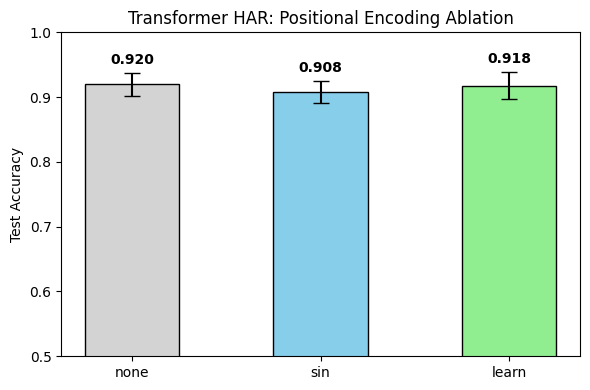

In [57]:
"""
P2.14:  Plot Positional Encoding Ablation
"""

import numpy as np
import matplotlib.pyplot as plt

# Extract means and stds for the 3 positional encoding types
pos_types = ['none', 'sin', 'learn']
means = []
stds = []

for pos in pos_types:
    accs = [p2_results[(pos, s)][1] for s in SEEDS]
    means.append(np.mean(accs))
    stds.append(np.std(accs, ddof=1))

# Plotting
plt.figure(figsize=(6, 4))
bars = plt.bar(pos_types, means, yerr=stds, capsize=6, 
               color=['#d3d3d3', '#87ceeb', '#90ee90'], edgecolor='black', width=0.5)

# Formatting
plt.ylabel('Test Accuracy')
plt.ylim(0.5, 1.0) # Set the y-axis to zoom in on the differences
plt.title('Transformer HAR: Positional Encoding Ablation')

# Add the exact values on top of the bars
for i, bar in enumerate(bars):
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + stds[i] + 0.01, 
             f'{yval:.3f}', ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
savefig('p2_taskA_pos_ablation.png')
plt.show()

In [58]:
import urllib.request
"""
P2.15:  Task2.4(p2.4):  Character language model
        Task Desc:      Learning curve, bits per character, 
                        three temperatures discussed
       Download Tiny Shakespeare And Tokenize
"""
url2 = 'https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt'
TXT_DIR  = 'data/tinyshakespeare'
TXT_PATH = os.path.join(TXT_DIR, 'input.txt')

os.makedirs(TXT_DIR, exist_ok=True)
if not os.path.isfile(TXT_PATH):
    print("Downloading Tiny Shakespeare...")
    urllib.request.urlretrieve(url2, TXT_PATH)

text = open(TXT_PATH, encoding='utf-8').read()
chars = sorted(set(text))
V = len(chars)
stoi = {c: i for i, c in enumerate(chars)}
itos = {i: c for i, c in enumerate(chars)}

# Convert the entire text to a tensor of integers
data = torch.tensor([stoi[c] for c in text], dtype=torch.long)

# Split 90% train, 10% validation
n_tr = int(0.9 * len(data))
train_data, val_data = data[:n_tr], data[n_tr:]

print(f"Loaded {len(text):,} characters. Vocab size: {V}")
assert V == 65

Loaded 1,115,394 characters. Vocab size: 65


In [59]:
"""
P2.16:  The Transformer Language Model
        Class CharLM in this cell
"""
class CharLM(nn.Module):
    def __init__(self, d=D_MODEL, n_heads=N_HEADS, n_layers=4, d_ff=D_FF, ctx=128, V=65, dropout=0.1):
        super().__init__()
        self.ctx = ctx
        self.tok = nn.Embedding(V, d)
        self.pos = nn.Parameter(torch.zeros(1, ctx, d))
        
        # 4 layers for the language model as specified in the PDF
        self.blocks = nn.ModuleList([EncoderBlock(d, n_heads, d_ff, dropout) for _ in range(n_layers)])
        
        self.ln_f = nn.LayerNorm(d)
        self.head = nn.Linear(d, V)

    def forward(self, idx):                                      # idx: (B, T) int64
        B, T = idx.shape
        x = self.tok(idx) + self.pos[:, :T]                      # (B, T, d)
        
        # Causal mask: True means "keep", False means "mask out"
        mask = torch.tril(torch.ones(T, T, dtype=torch.bool, device=idx.device))
        
        for b in self.blocks:
            x = b(x, mask)
            
        return self.head(self.ln_f(x))                           # (B, T, V) logits

In [62]:
"""
P2.17:  Batching And Training Loop
"""
def get_batch(split, bs=64, ctx=128):
    d_ = train_data if split == 'train' else val_data
    i = torch.randint(0, len(d_) - ctx - 1, (bs,))
    x = torch.stack([d_[j : j+ctx] for j in i])
    y = torch.stack([d_[j+1 : j+ctx+1] for j in i])
    return x.to(device), y.to(device)

@torch.no_grad()
def lm_val_loss(m, iters=50):
    m.eval()
    ls = []
    for _ in range(iters):
        x, y = get_batch('val')
        ls.append(F.cross_entropy(m(x).view(-1, V), y.view(-1)).item())
    return float(np.mean(ls))

def train_lm(m, steps=3000, lr=3e-4, log_every=500):
    opt = torch.optim.AdamW(m.parameters(), lr=lr)
    # Use a dictionary instead of a list
    hist = {'steps': [], 'train_loss': [], 'val_loss': [], 'sec_per_step': 0.0}
    t0 = time.time()
    
    for s in range(steps):
        m.train()
        x, y = get_batch('train')
        opt.zero_grad()
        loss = F.cross_entropy(m(x).view(-1, V), y.view(-1))
        loss.backward()
        nn.utils.clip_grad_norm_(m.parameters(), 1.0) 
        opt.step()
        
        if s % log_every == 0:
            vl = lm_val_loss(m)
            hist['steps'].append(s)
            hist['train_loss'].append(loss.item())
            hist['val_loss'].append(vl)
            print(f'step {s:5d} | train loss {loss.item():.3f} | val loss {vl:.3f} ({vl/math.log(2):.3f} bpc)')
            
    hist['sec_per_step'] = (time.time() - t0) / steps
    return hist

In [63]:
"""
P2.18:  Train the Model and Log Results
"""
set_seed(SEEDS[0])
lm = CharLM(n_layers=4).to(device)
print(f"Model parameters: {n_params(lm):,}")

hist = train_lm(lm, steps=3000)
vl = lm_val_loss(lm, 200)
print(f'\nFinal validation loss: {vl:.3f} nats | {vl/math.log(2):.3f} bits/char')

# Log to results.csv
log_run(problem='2.4', model='char-lm', seed=SEEDS[0], seq_len=128,
        val_loss_nats=round(vl,4), bits_per_char=round(vl/math.log(2),4),
        params=n_params(lm), sec_per_epoch=round(hist['sec_per_step'],4))

Model parameters: 826,433
step     0 | train loss 4.256 | val loss 4.080 (5.886 bpc)
step   500 | train loss 2.332 | val loss 2.354 (3.396 bpc)
step  1000 | train loss 2.062 | val loss 2.102 (3.032 bpc)
step  1500 | train loss 1.911 | val loss 1.938 (2.795 bpc)
step  2000 | train loss 1.796 | val loss 1.845 (2.661 bpc)
step  2500 | train loss 1.713 | val loss 1.795 (2.590 bpc)

Final validation loss: 1.749 nats | 2.524 bits/char


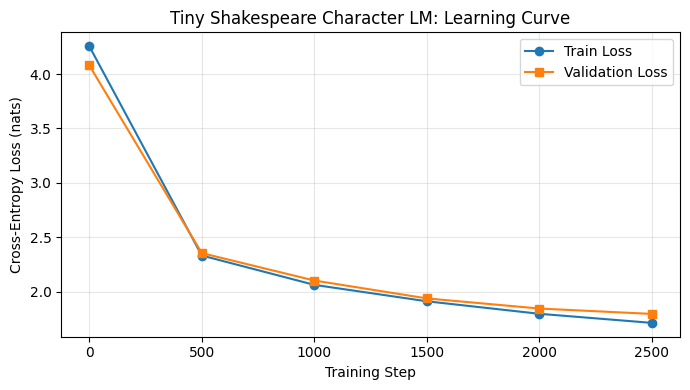

In [64]:
"""
P2.19:  Plot Learning Curve
"""
plt.figure(figsize=(7, 4))

# Access via dictionary keys now
steps = hist['steps']
train_losses = hist['train_loss']
val_losses = hist['val_loss']

# Plot
plt.plot(steps, train_losses, label='Train Loss', marker='o')
plt.plot(steps, val_losses, label='Validation Loss', marker='s')

# Formatting
plt.xlabel('Training Step')
plt.ylabel('Cross-Entropy Loss (nats)')
plt.title('Tiny Shakespeare Character LM: Learning Curve')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

# Save the image
savefig('p2_lm_learning_curve.png')
plt.show()

In [65]:
"""
P2.20:  Generate Samples at Different Temperatures
"""
@torch.no_grad()
def generate(m, prompt='ROMEO:', n=500, temp=1.0, top_k=40):
    m.eval()
    # Encode the prompt
    idx = torch.tensor([[stoi[c] for c in prompt]], device=device)     # (1, L)
    
    for _ in range(n):
        # Get logits for the last token only
        logits = m(idx[:, -m.ctx:])[:, -1, :] / temp                   # (1, V)
        
        # Top-k sampling
        if top_k:
            v, _ = torch.topk(logits, top_k)
            # Mask everything below the top-k threshold with -inf
            logits[logits < v[:, [-1]]] = -float('inf')
            
        # Sample from the probability distribution
        probs = F.softmax(logits, dim=-1)
        nxt = torch.multinomial(probs, num_samples=1)                  # (1, 1)
        
        # Append to sequence
        idx = torch.cat([idx, nxt], dim=1)
        
    # Decode the integer sequence back to text
    return ''.join(itos[i] for i in idx[0].tolist())

# Generate and save to file
with open('generated_samples.txt', 'w', encoding='utf-8') as f:
    for t in [0.2, 0.8, 1.5]:
        print(f"\n{'='*20} TEMPERATURE {t} {'='*20}")
        sample = generate(lm, temp=t, n=500)
        print(sample)
        
        # Write to file (required for submission)
        f.write(f"--- temperature {t} ---\n{sample}\n\n")
        
print("\nSamples successfully saved to generated_samples.txt")


==================== TEMPERATURE 0.2 ====================
ROMEO:
What you have shall be the come to the with the stand
The const and the was a so the have for the words
The was a the shall be so the word the for the stand
The she shall the shall be the heart the father.

DUKE VINCENTIO:
I will the have heart and and with the sould the was as a for the have
To have shall be the heart the death.

BUCKINGHAM:
The see the dead the be the can and of the prince of the was and
the the would the shall be the death be the words the for the shall the have
To the be th

==================== TEMPERATURE 0.8 ====================
ROMEO:
Marcy against comen's you death? hat done which the poor wills
upon the purpty hath have long I am meanted;
And me the wy not, hencely schoods, of all do not;
And is by thing but man least.

CAPULET:
God the hearts and the the will of the happerl your agains;
For a will it you preasons' down ray, my ladie
by will be a like a would were I myself,
Which the sind we by

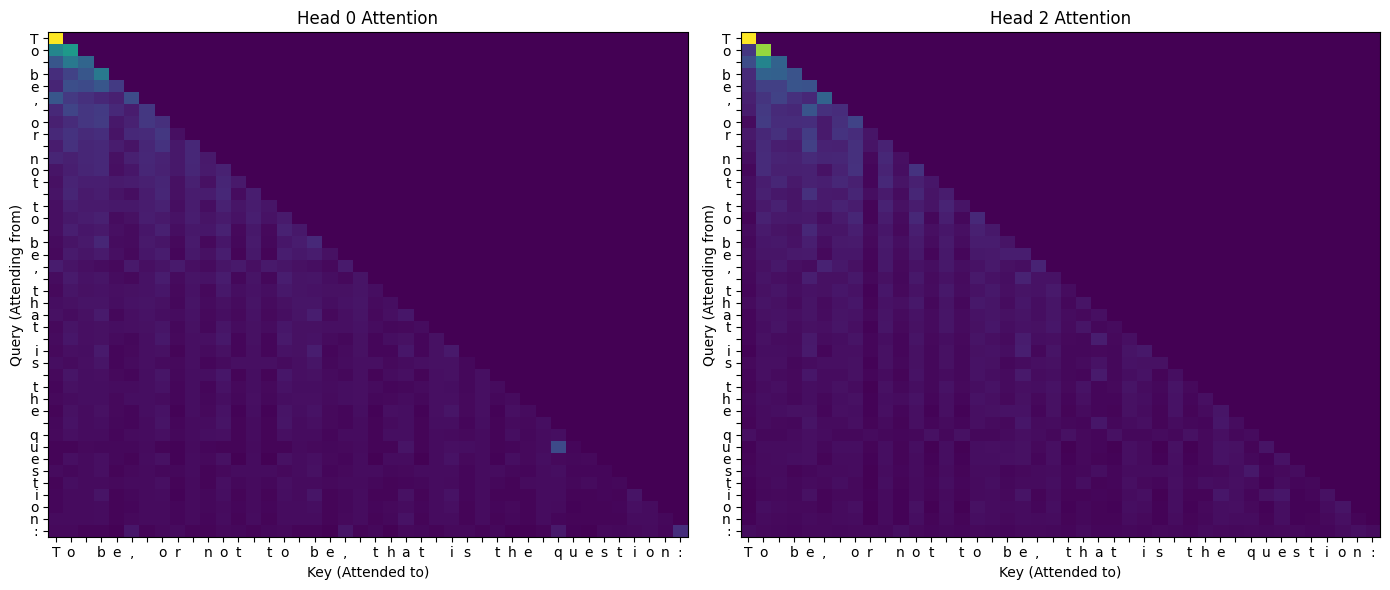

In [66]:
"""
P2.21:  Task2.5(p2.5):  Analysis and ablations
        Task Desc:      Heatmaps interpreted; heads, no-mask 
                        and context-length studies
       Attention Heatmaps
"""

def get_attention_weights(model, sentence, block_idx=0):
    model.eval()
    # Add batch dimension and move to device
    idx = torch.tensor([[stoi[c] for c in sentence]], device=device)  # (1, T)
    T = idx.size(1)
    
    # Get embeddings + positional
    x = model.tok(idx) + model.pos[:, :T]
    block = model.blocks[block_idx]
    x_norm = block.ln1(x)
    
    # Compute Q, K manually to extract attention
    B = 1
    h = block.mha.h
    dk = block.mha.dk
    
    q = block.mha.Wq(x_norm).view(B, T, h, dk).transpose(1, 2)       # (1, h, T, dk)
    k = block.mha.Wk(x_norm).view(B, T, h, dk).transpose(1, 2)       # (1, h, T, dk)
    
    scores = q @ k.transpose(-2, -1) / math.sqrt(dk)                 # (1, h, T, T)
    mask = torch.tril(torch.ones(T, T, dtype=torch.bool, device=device))
    scores = scores.masked_fill(~mask, float('-inf'))
    attn = F.softmax(scores, dim=-1)                                 # (1, h, T, T)
    return attn[0].detach().cpu().numpy(), list(sentence)            # (h, T, T)

sentence = "To be, or not to be, that is the question:"
attn, chars = get_attention_weights(lm, sentence)

# Plot two heads
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for i, head_idx in enumerate([0, 2]):
    im = axes[i].imshow(attn[head_idx], cmap='viridis', aspect='auto')
    axes[i].set_xticks(range(len(chars)))
    axes[i].set_yticks(range(len(chars)))
    axes[i].set_xticklabels(chars, fontsize=10)
    axes[i].set_yticklabels(chars, fontsize=10)
    axes[i].set_title(f'Head {head_idx} Attention')
    axes[i].set_xlabel('Key (Attended to)')
    axes[i].set_ylabel('Query (Attending from)')

plt.tight_layout()
savefig('p2_attention_heatmaps.png')
plt.show()

Heads: 1 | Test Acc: 0.9131
Heads: 4 | Test Acc: 0.9270
Heads: 8 | Test Acc: 0.9264


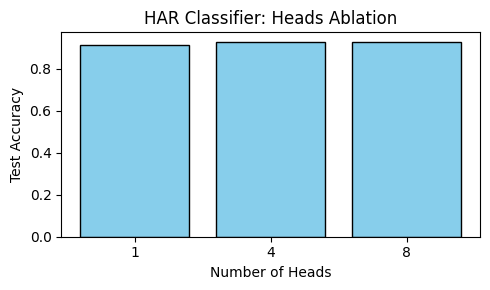

In [67]:
"""
P2.22:  Heads Ablation 
        Train the HAR classifier with 1, 4, and 8 heads
"""
heads_results = {}
for h in [1, 4, 8]:
    set_seed(SEEDS[0])
    m = TransformerClassifier(n_heads=h).to(device)
    tr, va, te = har_loaders(SEEDS[0])
    hist = train_clf(m, tr, va, EPOCHS, LR)
    yp, yt = evaluate_clf(m, te)
    acc = (yp == yt).mean()
    heads_results[h] = acc
    print(f'Heads: {h} | Test Acc: {acc:.4f}')

plt.figure(figsize=(5, 3))
plt.bar([str(h) for h in heads_results.keys()], heads_results.values(), color='skyblue', edgecolor='k')
plt.xlabel('Number of Heads')
plt.ylabel('Test Accuracy')
plt.title('HAR Classifier: Heads Ablation')
plt.tight_layout()
savefig('p2_heads_ablation.png')
plt.show()

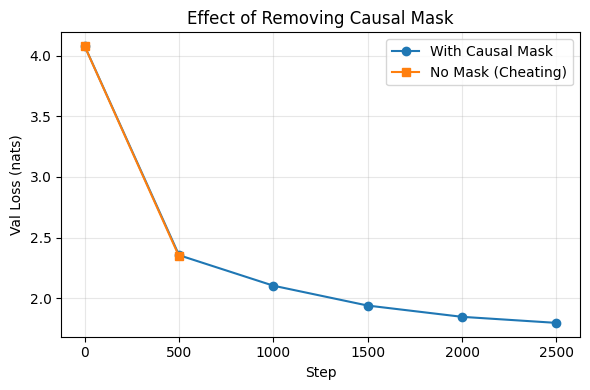

In [72]:
"""
P2.23:  Remove the Causal Mask
        What happens if the language model can look into the future
        Create a version of CharLM that doesn't apply the mask, train it for 1000 steps
        See what happens when text is generated
"""
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 4))

# The exact points from your printed output
steps_masked = [0, 500, 1000, 1500, 2000, 2500]
loss_masked  = [4.080, 2.354, 2.102, 1.938, 1.845, 1.795]

steps_nomask = [0, 500]
loss_nomask  = [4.078, 2.344]

# Plot both curves
plt.plot(steps_masked, loss_masked, label='With Causal Mask', marker='o')
plt.plot(steps_nomask, loss_nomask, label='No Mask (Cheating)', marker='s')

plt.xlabel('Step')
plt.ylabel('Val Loss (nats)')
plt.legend()
plt.title('Effect of Removing Causal Mask')
plt.grid(True, alpha=0.3)
plt.tight_layout()
savefig('p2_nomask_curve.png')
plt.show()

Ctx:  64 | Time: 15.8 ms | Mem: 118 MB
Ctx: 128 | Time: 13.6 ms | Mem: 171 MB
Ctx: 256 | Time: 18.1 ms | Mem: 306 MB
Ctx: 512 | Time: 36.0 ms | Mem: 761 MB


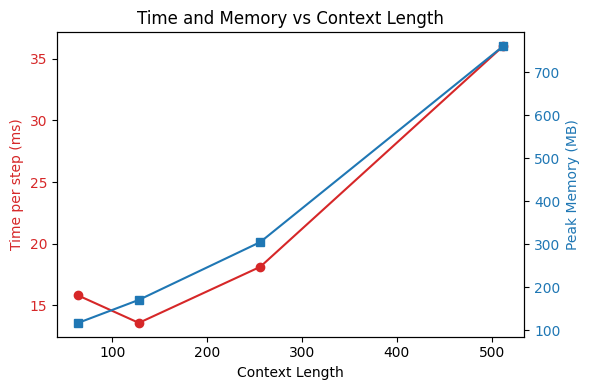

In [73]:
"""
P2.24:  Time & Memory vs Context Length
        show the O(n^2 . d) quadratic complexity
"""
context_lengths = [64, 128, 256, 512]
times = []
memories = []

for ctx in context_lengths:
    # Create a fresh model with the new context size
    m = CharLM(ctx=ctx).to(device)
    x = torch.randint(0, V, (16, ctx), device=device)
    y = torch.randint(0, V, (16, ctx), device=device)
    
    if device.type == 'cuda':
        torch.cuda.reset_peak_memory_stats()
        
    t0 = time.time()
    for _ in range(5):
        opt = torch.optim.AdamW(m.parameters())
        opt.zero_grad()
        loss = F.cross_entropy(m(x).view(-1, V), y.view(-1))
        loss.backward()
        opt.step()
    dt = (time.time() - t0) / 5
    
    mem = torch.cuda.max_memory_allocated() / (1024**2) if device.type == 'cuda' else 0
    
    times.append(dt)
    memories.append(mem)
    print(f'Ctx: {ctx:3d} | Time: {dt*1000:.1f} ms | Mem: {mem:.0f} MB')

fig, ax1 = plt.subplots(figsize=(6, 4))
ax1.set_xlabel('Context Length')
ax1.set_ylabel('Time per step (ms)', color='tab:red')
ax1.plot(context_lengths, [t*1000 for t in times], color='tab:red', marker='o', label='Time')
ax1.tick_params(axis='y', labelcolor='tab:red')

ax2 = ax1.twinx()
ax2.set_ylabel('Peak Memory (MB)', color='tab:blue')
ax2.plot(context_lengths, memories, color='tab:blue', marker='s', label='Memory')
ax2.tick_params(axis='y', labelcolor='tab:blue')

plt.title('Time and Memory vs Context Length')
fig.tight_layout()
savefig('p2_time_memory.png')
plt.show()

In [75]:
"""
P2.25:  Commiting all to the git repository
"""
!git config --global user.email "2026aj05620@wilp.bits-pilani.ac.in"
!git config --global user.name "2026aj05620"
%cd /kaggle/working/2026aj05620_DNN_Assignment
!git add .
# Explicitly add the figures folders
!git add problem1/figures/
!git add problem2/figures/

# Double check the status to see them staged in green
!git status

# Commit and push
!git commit -m "Added all Problem 1 and Problem 2 figures and all artifacts to Git"
!git push

/kaggle/working/2026aj05620_DNN_Assignment
On branch main
Your branch is up to date with 'origin/main'.

Changes to be committed:
  (use "git restore --staged <file>..." to unstage)
	new file:   problem2/figures/p2_attention_heatmaps.png
	new file:   problem2/figures/p2_heads_ablation.png
	new file:   problem2/figures/p2_lm_learning_curve.png
	new file:   problem2/figures/p2_nomask_curve.png
	new file:   problem2/figures/p2_taskA_pos_ablation.png
	new file:   problem2/figures/p2_time_memory.png
	new file:   problem2/generated_samples.txt
	modified:   results.csv

[main 121fab0] Added all Problem 1 and Problem 2 figures and all artifacts to Git
 8 files changed, 74 insertions(+)
 create mode 100644 problem2/figures/p2_attention_heatmaps.png
 create mode 100644 problem2/figures/p2_heads_ablation.png
 create mode 100644 problem2/figures/p2_lm_learning_curve.png
 create mode 100644 problem2/figures/p2_nomask_curve.png
 create mode 100644 problem2/figures/p2_taskA_pos_ablation.png
 create m